# 潮汐中的失衡：厦门市共享单车早高峰供需潮汐的时空特征与天气效应

**CISC7204 – Data Science and Data Visualization** ｜ 学生：ZHOU YUYI（MC641857）

**研究问题**：在厦门市早高峰时段（6:00–10:00 AM），共享单车潮汐失衡在哪些具体区域和时段最为严重？天气条件（温度、降水、风速、湿度）对潮汐失衡程度的边际效应有多大？

**数据集**（2020-12-21 ~ 2020-12-25，五个工作日早高峰 6:00–10:00）：

| 数据 | 规模 | 说明 |
|---|---|---|
| 订单数据 | 220,675 单（441,350 条解锁/上锁事件） | 起终点 GPS、锁状态、时间戳、行程时长 |
| 轨迹数据 | 2,849,243 个 GPS 点 | 30s–2min 采样，5 个日文件 |
| 电子围栏 | 10,522 条原始记录（去重后 10,517 个） | 四角坐标多边形 |
| 天气数据 | 144 条逐小时观测 | 温度/湿度/风/气压（日照/降水/阵风列缺失） |

**Notebook 结构**（对应 Proposal 的 Task 1–5）：

1. **Task 1** 数据获取、清洗与质量报告（含数据字典）
2. **Task 2** 潮汐失衡量化与时空特征分析（产出**图1** 热力图、聚类、热点清单）
3. **Task 3** 天气效应统计建模（产出**图2** 系数森林图、**图3** 预测-实际散点图）
4. **Task 4** 调度优化空间模拟（调度前后对比表与对比图）
5. **Task 5** 可视化与交互式仪表盘（产出**图4** Folium 地图仪表盘）

**运行方式**：内核选择 `python3`；依赖 pandas / numpy / matplotlib / seaborn / scikit-learn / scipy / statsmodels / openpyxl / folium（Anaconda 基础环境已内置；xgboost 可选安装）。数据路径与输出目录在下方配置单元格中修改。全流程预计运行 3–6 分钟。

## 0. 环境与全局配置

In [1]:
import os, re, sys, time, json, warnings, ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

from scipy.spatial import cKDTree
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestRegressor
import statsmodels.api as sm
from IPython.display import display

try:
    import xgboost as xgb
    HAS_XGB = True
except Exception:
    HAS_XGB = False

try:
    import folium
    from branca.colormap import LinearColormap
    HAS_FOLIUM = True
except Exception:
    HAS_FOLIUM = False

try:
    from sklearn.metrics import root_mean_squared_error as _rmse
except ImportError:
    _rmse = lambda a, b: mean_squared_error(a, b, squared=False)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
np.random.seed(42)

sns.set_style('whitegrid')   # 注意：必须先设置 seaborn 样式，再设置中文字体（set_style 会重置字体列表）

# 中文字体（按系统可用字体自动选择）
_cjk = ['PingFang SC', 'Hiragino Sans GB', 'Heiti SC', 'Arial Unicode MS',
        'Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'WenQuanYi Zen Hei']
_avail = {f.name for f in fm.fontManager.ttflist}
for _f in _cjk:
    if _f in _avail:
        plt.rcParams['font.sans-serif'] = [_f]
        break
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110

print('Python', sys.version.split()[0])
print('pandas', pd.__version__, '| numpy', np.__version__, '| sklearn', __import__('sklearn').__version__)
print('XGBoost 可用:', HAS_XGB, '| Folium 可用:', HAS_FOLIUM)

# ---------------- 全局配置（按需修改） ----------------
DATA_ROOT = Path('/Users/Zyy/Desktop/data science and data visualization/assignment01/proposal/Shared bicycle data')
OUTPUT_DIR = Path.cwd() / 'outputs'          # 输出目录（位于 notebook 所在目录的 outputs/ 下）
FIG_DIR = OUTPUT_DIR / 'figs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

PEAK_START, PEAK_END = '06:00', '10:00'      # 早高峰窗口
SLOT_MIN = 30                                 # 时间粒度（分钟）
ASSIGN_MAX_DIST = 500.0                       # 事件归属电子围栏的最大距离（米）
ACTIVE_MIN_EVENTS = 20                        # “活跃围栏”筛选阈值（5 天总事件数）
N_CLUSTERS = 4                                # 潮汐模式聚类簇数（参照原研究 k=4）
DBSCAN_EPS_M = 700.0                          # 空间聚类邻域（米，参照原研究 700m 阈值）
SEED = 42

XIA_MEN_REF = (24.50, 118.15)                 # 局部投影参考点
def to_meters(lat, lng):
    lat0, lng0 = XIA_MEN_REF
    x = (lng - lng0) * 111320.0 * np.cos(np.radians(lat0))
    y = (lat - lat0) * 110540.0
    return x, y

print('数据目录:', DATA_ROOT)
print('输出目录:', OUTPUT_DIR)

Python 3.14.6
pandas 3.0.3 | numpy 2.4.6 | sklearn 1.9.0
XGBoost 可用: False | Folium 可用: True
数据目录: /Users/Zyy/Desktop/data science and data visualization/assignment01/proposal/Shared bicycle data
输出目录: /Users/Zyy/Desktop/data science and data visualization/assignment01/proposal/outputs


## Task 1 · 数据获取、清洗与质量报告

> 注意：数据集目录中的 `order data.csv`、`STATION.csv`、轨迹日文件虽以 `.csv` 命名，实际是 **Excel 2007+ 工作簿**（天气数据才是真正的 CSV 文本），因此统一用 `pd.read_excel` 读取。

### 1.1 订单数据加载与清洗

In [2]:
ORDER_FILE = DATA_ROOT / 'Order data' / 'order data.csv'
orders_raw = pd.read_excel(ORDER_FILE)
print('原始订单事件数:', f'{len(orders_raw):,}')

orders = orders_raw.copy()
# 1) 车辆 ID 前向填充（Excel 报表中同一车辆仅首行显示 ID）
orders['BICYCLE_ID'] = orders['BICYCLE_ID'].ffill()
# 2) 合并日期 + 时间 → 完整时间戳（UTC+8）
orders['TS'] = pd.to_datetime(orders['UPDATE_TIME1'].astype(str) + ' ' + orders['UPDATE_TIME2'].astype(str))
orders['DATE'] = orders['TS'].dt.date.astype(str)
orders['HOUR'] = orders['TS'].dt.hour
orders['SLOT'] = (orders['TS'].dt.hour * 60 + orders['TS'].dt.minute) // 30   # 30 分钟时段编号
orders['ORDER DURATION'] = pd.to_numeric(orders['ORDER DURATION'], errors='coerce')

print('解锁事件(LOCK_STATUS=0):', f"{(orders['LOCK_STATUS']==0).sum():,}")
print('上锁事件(LOCK_STATUS=1):', f"{(orders['LOCK_STATUS']==1).sum():,}")
print('有效订单数（=上锁事件数）:', f"{(orders['LOCK_STATUS']==1).sum():,}  ← 与 Proposal 的 220,675 一致")
print('车辆数:', f"{orders['BICYCLE_ID'].nunique():,}")
print('日期范围:', orders['DATE'].min(), '~', orders['DATE'].max())
print('小时范围:', orders['HOUR'].min(), ':00 ~', orders['HOUR'].max(), ':59（早高峰子集）')
print('缺失值:\n', orders.isna().sum().to_string())
print('\n坐标范围: LAT %.5f~%.5f, LNG %.5f~%.5f' % (orders['LATITUDE'].min(), orders['LATITUDE'].max(),
                                                  orders['LONGITUDE'].min(), orders['LONGITUDE'].max()))
print('重复行:', int(orders.duplicated().sum()))

原始订单事件数: 441,350


解锁事件(LOCK_STATUS=0): 220,675
上锁事件(LOCK_STATUS=1): 220,675
有效订单数（=上锁事件数）: 220,675  ← 与 Proposal 的 220,675 一致
车辆数: 52,933
日期范围: 2020-12-21 ~ 2020-12-25
小时范围: 6 :00 ~ 9 :59（早高峰子集）
缺失值:
 BICYCLE_ID             0
LATITUDE               0
LONGITUDE              0
LOCK_STATUS            0
UPDATE_TIME1           0
UPDATE_TIME2           0
ORDER DURATION    220675
TS                     0
DATE                   0
HOUR                   0
SLOT                   0

坐标范围: LAT 24.42616~24.55908, LNG 118.05891~118.19588
重复行: 0


In [3]:
STATION_FILE = DATA_ROOT / 'Electronic fence data' / 'STATION.csv'
station_raw = pd.read_excel(STATION_FILE)
station_dup = int(station_raw['FENCE_ID'].duplicated().sum())
print('原始围栏记录数:', len(station_raw), '| 重复 FENCE_ID:', station_dup, '（已去重，保留首条）')
station_raw = station_raw.drop_duplicates('FENCE_ID').reset_index(drop=True)

def _parse_fence(s):
    pts = np.array(ast.literal_eval(s))            # 每个顶点为 [经度, 纬度]
    lat, lng = pts[:, 1].mean(), pts[:, 0].mean()  # 多边形质心
    x, y = to_meters(pts[:, 1], pts[:, 0])         # 转为米制求面积（鞋带公式）
    area = 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))
    return pd.Series({'LAT': lat, 'LNG': lng, 'AREA_M2': area, 'N_PTS': len(pts)})

stations = pd.concat([station_raw, station_raw['FENCE_LOC'].apply(_parse_fence)], axis=1)
print('去重后电子围栏数:', len(stations))
print(stations[['LAT', 'LNG', 'AREA_M2', 'N_PTS']].describe().round(2).to_string())

原始围栏记录数: 10522 | 重复 FENCE_ID: 5 （已去重，保留首条）


去重后电子围栏数: 10517
            LAT       LNG   AREA_M2    N_PTS
count  10517.00  10517.00  10517.00  10517.0
mean      24.50    118.12     11.97      5.0
std        0.02      0.03      7.26      0.0
min       24.43    118.07      1.58      5.0
25%       24.48    118.10      7.98      5.0
50%       24.50    118.12     10.12      5.0
75%       24.52    118.15     13.96      5.0
max       24.56    118.19    213.18      5.0


In [4]:
TRAJ_DIR = DATA_ROOT / 'Trajectory data'
traj_files = sorted(TRAJ_DIR.glob('*.csv'))
print('轨迹日文件:', [f.name for f in traj_files])
traj_list = []
for f in traj_files:
    t0 = time.time()
    d = pd.read_excel(f)
    d['BICYCLE_ID'] = d['BICYCLE_ID'].ffill()
    day = re.search(r'(\d{8})', f.name).group(1)
    d['DATE'] = f'{day[:4]}-{day[4:6]}-{day[6:]}'
    d['TS'] = pd.to_datetime(d['DATE'] + ' ' + d['LOCATING_TIME'].astype(str))
    traj_list.append(d)
    print(f'  加载 {f.name}: {len(d):,} 行（{time.time()-t0:.1f}s）')
traj = pd.concat(traj_list, ignore_index=True)
print('\n轨迹总点数:', f'{len(traj):,}', '← 与 Proposal 的 2,849,243 一致')
print('轨迹车辆数:', f"{traj['BICYCLE_ID'].nunique():,}")
print('坐标范围: LAT %.5f~%.5f, LNG %.5f~%.5f' % (traj['LATITUDE'].min(), traj['LATITUDE'].max(),
                                                traj['LONGITUDE'].min(), traj['LONGITUDE'].max()))

轨迹日文件: ['Trajectory data_20201221.csv', 'Trajectory data_20201222.csv', 'Trajectory data_20201223.csv', 'Trajectory data_20201224.csv', 'Trajectory data_20201225.csv']


  加载 Trajectory data_20201221.csv: 542,386 行（9.4s）


  加载 Trajectory data_20201222.csv: 586,562 行（10.2s）


  加载 Trajectory data_20201223.csv: 213,733 行（3.7s）


  加载 Trajectory data_20201224.csv: 932,469 行（16.5s）


  加载 Trajectory data_20201225.csv: 574,093 行（9.7s）

轨迹总点数: 2,849,243 ← 与 Proposal 的 2,849,243 一致
轨迹车辆数: 14,394
坐标范围: LAT 24.42518~24.62459, LNG 118.02246~118.32280


In [5]:
WEATHER_FILE = DATA_ROOT / 'Weather data' / 'Weather data.csv'
weather = pd.read_csv(WEATHER_FILE)
weather['TIME'] = pd.to_datetime(weather['TIME'])
weather['DATE'] = weather['TIME'].dt.date.astype(str)
weather['HOUR'] = weather['TIME'].dt.hour
print('天气观测数:', len(weather), '| 范围:', weather['TIME'].min(), '~', weather['TIME'].max())
print('\n各列缺失值:')
print(weather.isna().sum().to_string())
print('\n早高峰（6–9 时）可用天气变量描述统计:')
print(weather[(weather['HOUR'] >= 6) & (weather['HOUR'] <= 9)][['TEMP', 'RHUM', 'WSPD', 'PRES']].describe().round(2).to_string())
print('\n[数据局限说明] 观测窗口内 PRCP（降水）/SNOW（降雪）/TSUN（日照）/WPGT（阵风）四列全部缺失：')
print('· 该 5 天为无降水天气，PRCP/SNOW 按 0（无降水）处理；')
print('· TSUN（日照）、WPGT（阵风）无任何观测，无法建模，后续从特征中剔除；')
print('· 因此本窗口无法估计“降水/日照/阵风”的边际效应——如实标注的数据局限。')
print('可用于建模的天气变量：TEMP 温度、RHUM 相对湿度、WSPD 风速、PRES 气压、COCO 天气现象代码。')
weather['PRCP'] = weather['PRCP'].fillna(0.0)
weather['SNOW'] = weather['SNOW'].fillna(0.0)

天气观测数: 144 | 范围: 2020-12-20 00:00:00 ~ 2020-12-25 23:00:00

各列缺失值:
TIME      0
TEMP      0
DWPT      0
RHUM      0
PRCP    144
SNOW    144
WDIR      0
WSPD      0
WPGT    144
PRES      0
TSUN    144
COCO      0
DATE      0
HOUR      0

早高峰（6–9 时）可用天气变量描述统计:
        TEMP    RHUM   WSPD     PRES
count  24.00   24.00  24.00    24.00
mean   15.07   73.33  10.65  1022.19
std     1.01   17.03   5.14     3.47
min    13.50   51.00   0.00  1016.00
25%    14.08   59.00   7.20  1019.75
50%    15.00   64.00  10.80  1022.50
75%    16.00   94.00  14.40  1025.15
max    17.00  100.00  21.60  1027.70

[数据局限说明] 观测窗口内 PRCP（降水）/SNOW（降雪）/TSUN（日照）/WPGT（阵风）四列全部缺失：
· 该 5 天为无降水天气，PRCP/SNOW 按 0（无降水）处理；
· TSUN（日照）、WPGT（阵风）无任何观测，无法建模，后续从特征中剔除；
· 因此本窗口无法估计“降水/日照/阵风”的边际效应——如实标注的数据局限。
可用于建模的天气变量：TEMP 温度、RHUM 相对湿度、WSPD 风速、PRES 气压、COCO 天气现象代码。


,数据集,记录数,缺失值,重复项,时间范围,坐标范围
0,订单数据,"441,350",0（ID/坐标/时间戳完整）,0,2020-12-21 ~ 12-25（6:00–9:59）,LAT 24.426~24.559\nLNG 118.059~118.196
1,轨迹数据,"2,849,243",0（ID/坐标/时间完整）,0,2020-12-21 ~ 12-25（6:00–9:59）,LAT 24.425~24.625\nLNG 118.022~118.323
2,电子围栏,"10,517",0,FENCE_ID 重复 5 个已去重,—,LAT 24.427~24.558\nLNG 118.067~118.193
3,天气数据,144,PRCP/SNOW 全缺失 → 按 0（无降水）处理,0,2020-12-20 ~ 12-25（逐小时）,—


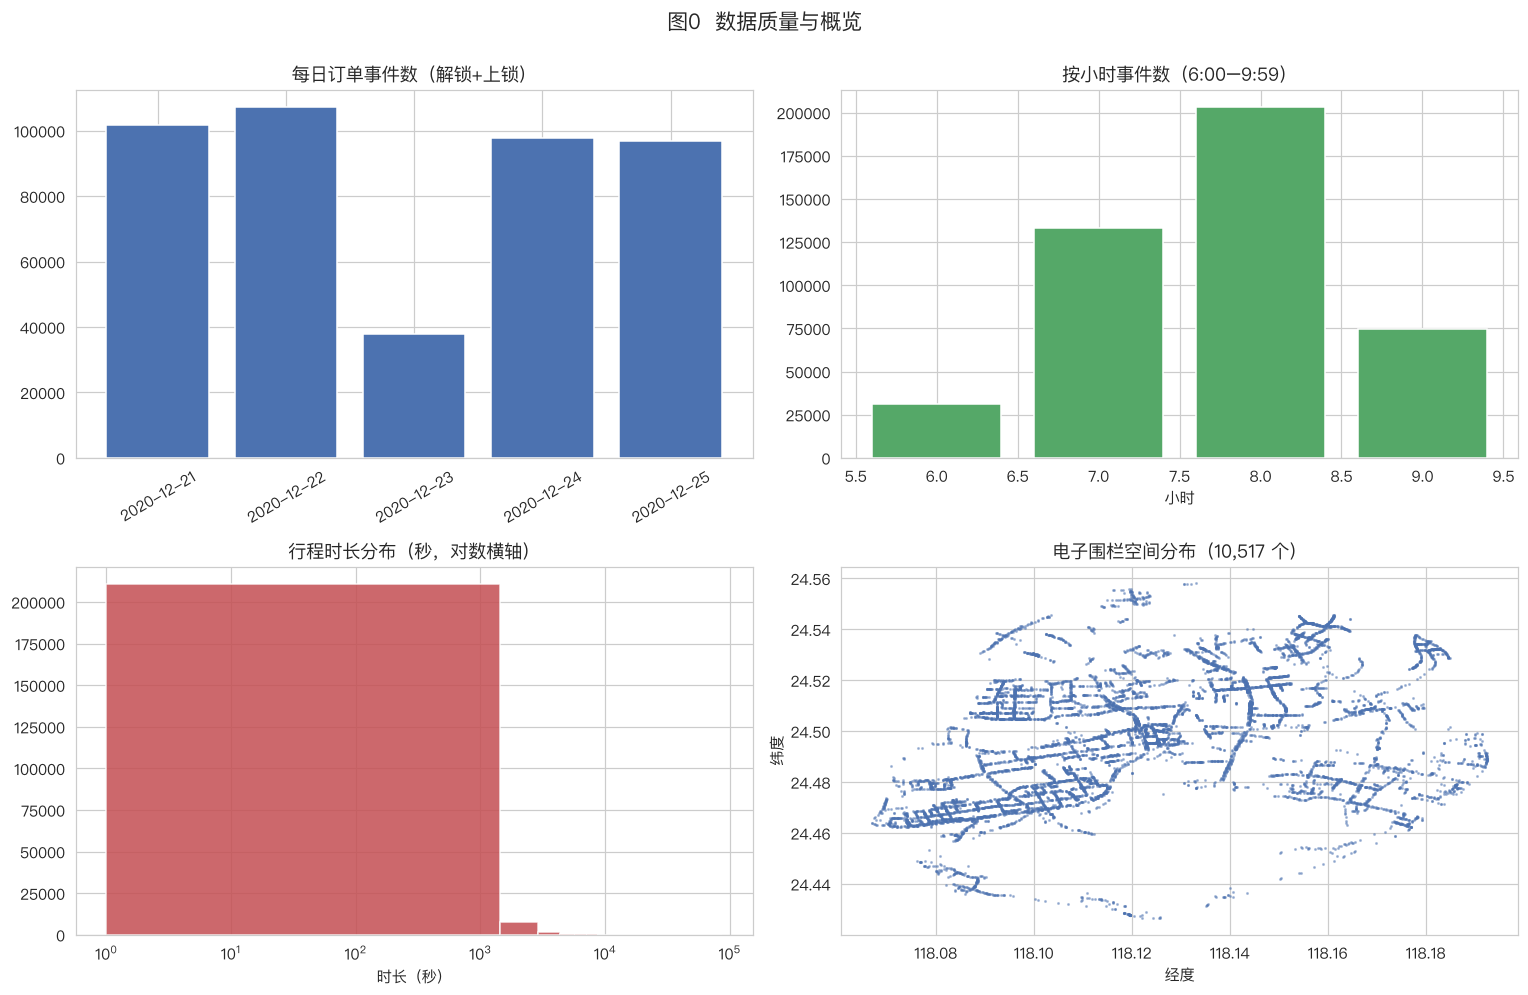

In [6]:
# 数据质量总报告
report = pd.DataFrame({
    '数据集': ['订单数据', '轨迹数据', '电子围栏', '天气数据'],
    '记录数': [f'{len(orders):,}', f'{len(traj):,}', f'{len(stations):,}', f'{len(weather):,}'],
    '缺失值': ['0（ID/坐标/时间戳完整）', '0（ID/坐标/时间完整）', '0',
             'PRCP/SNOW 全缺失 → 按 0（无降水）处理'],
    '重复项': [f'{int(orders.duplicated().sum()):,}', f'{int(traj.duplicated().sum()):,}',
             f'FENCE_ID 重复 {station_dup} 个已去重', '0'],
    '时间范围': ['2020-12-21 ~ 12-25（6:00–9:59）', '2020-12-21 ~ 12-25（6:00–9:59）',
              '—', '2020-12-20 ~ 12-25（逐小时）'],
    '坐标范围': [f'LAT {orders["LATITUDE"].min():.3f}~{orders["LATITUDE"].max():.3f}\nLNG {orders["LONGITUDE"].min():.3f}~{orders["LONGITUDE"].max():.3f}',
              f'LAT {traj["LATITUDE"].min():.3f}~{traj["LATITUDE"].max():.3f}\nLNG {traj["LONGITUDE"].min():.3f}~{traj["LONGITUDE"].max():.3f}',
              f'LAT {stations["LAT"].min():.3f}~{stations["LAT"].max():.3f}\nLNG {stations["LNG"].min():.3f}~{stations["LNG"].max():.3f}',
              '—'],
})
display(report)

# 数据概览图
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
daily = orders.groupby('DATE').size()
axes[0, 0].bar(daily.index, daily.values, color='#4C72B0')
axes[0, 0].set_title('每日订单事件数（解锁+上锁）')
axes[0, 0].tick_params(axis='x', rotation=30)
hourly = orders.groupby('HOUR').size()
axes[0, 1].bar(hourly.index, hourly.values, color='#55A868')
axes[0, 1].set_title('按小时事件数（6:00–9:59）')
axes[0, 1].set_xlabel('小时')
durations = orders.loc[orders['LOCK_STATUS'] == 1, 'ORDER DURATION'].dropna()
axes[1, 0].hist(durations, bins=60, color='#C44E52', alpha=.85)
axes[1, 0].set_xscale('log')
axes[1, 0].set_title('行程时长分布（秒，对数横轴）')
axes[1, 0].set_xlabel('时长（秒）')
axes[1, 1].scatter(stations['LNG'], stations['LAT'], s=1, c='#4C72B0', alpha=.4)
axes[1, 1].set_title(f'电子围栏空间分布（{len(stations):,} 个）')
axes[1, 1].set_xlabel('经度'); axes[1, 1].set_ylabel('纬度')
fig.suptitle('图0  数据质量与概览', y=1.0, fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig0_data_overview.png', dpi=130, bbox_inches='tight')
plt.show()

示例车辆 BICYCLE_7488：2020-12-21 早高峰 724 个轨迹点，08:16:41 → 09:30:18


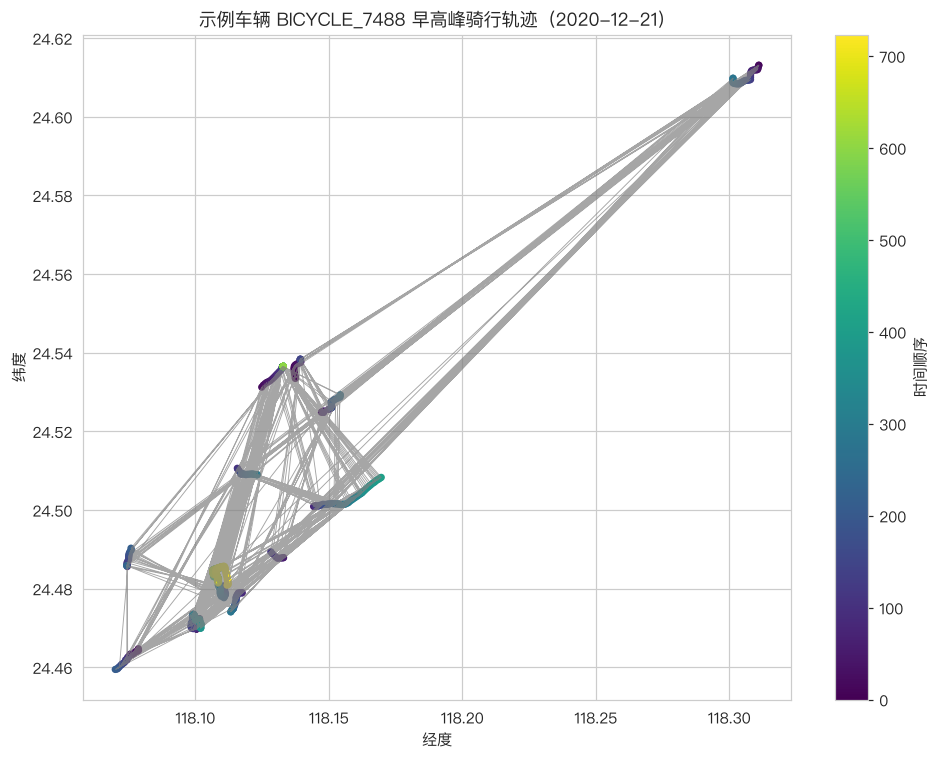

In [7]:
# 示例：单辆车的早高峰骑行轨迹（轨迹数据可视化）
day_ex = '2020-12-21'
sub = traj[traj['DATE'] == day_ex]
bike_ex = sub['BICYCLE_ID'].value_counts().index[0]
one = sub[sub['BICYCLE_ID'] == bike_ex].sort_values('TS')
print(f'示例车辆 {bike_ex}：{day_ex} 早高峰 {len(one):,} 个轨迹点，'
      f'{one["TS"].iloc[0].strftime("%H:%M:%S")} → {one["TS"].iloc[-1].strftime("%H:%M:%S")}')
fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(one['LONGITUDE'], one['LATITUDE'], c=np.arange(len(one)), cmap='viridis', s=14)
ax.plot(one['LONGITUDE'], one['LATITUDE'], lw=.6, color='gray', alpha=.7)
plt.colorbar(sc, ax=ax, label='时间顺序')
ax.set_title(f'示例车辆 {bike_ex} 早高峰骑行轨迹（{day_ex}）')
ax.set_xlabel('经度'); ax.set_ylabel('纬度')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig0_sample_route.png', dpi=130, bbox_inches='tight')
plt.show()

In [8]:
# 保存清洗后的数据（供后续复用与报告附件）
orders.to_csv(OUTPUT_DIR / 'orders_clean.csv', index=False)
stations[['FENCE_ID', 'LAT', 'LNG', 'AREA_M2', 'N_PTS']].to_csv(OUTPUT_DIR / 'stations_clean.csv', index=False)
weather.to_csv(OUTPUT_DIR / 'weather_clean.csv', index=False)
traj.sample(n=min(200000, len(traj)), random_state=SEED).to_csv(OUTPUT_DIR / 'trajectory_sample.csv', index=False)
print('Task 1 输出已保存：', sorted(p.name for p in OUTPUT_DIR.glob('*')))

Task 1 输出已保存： ['figs', 'orders_clean.csv', 'stations_clean.csv', 'trajectory_sample.csv', 'weather_clean.csv']


## Task 2 · 潮汐失衡量化与时空特征分析

**方法**：
1. **事件归属**：将每条解锁/上锁事件按 GPS 坐标归属到最近的电子围栏质心（≤500m，局部米制投影 + cKDTree）；
2. **流量统计**：按 30 分钟粒度统计每个围栏的流入（上锁）与流出（解锁），净流入 = 流入 − 流出；
3. **失衡指数**：用「经验容量」（观测窗口内围栏驻车量的最大振幅 max−min 并发驻车数）将净流入标准化为容量百分比 —— 正值为淤积（车辆过剩），负值为缺车（车辆不足）；
4. **时空聚类**：对活跃围栏的 8 个时段失衡剖面做 KMeans 聚类（参照原研究 k=4），识别“先入后出/先出后入”等潮汐模式；
5. **空间聚类**：DBSCAN（haversine 距离，eps=700m）识别空间区域簇；
6. **热点识别**：输出早高峰最严重的缺车/淤积围栏清单。

In [9]:
# 事件 → 电子围栏归属（最近质心，≤500m）
tree = cKDTree(np.c_[to_meters(stations['LAT'].values, stations['LNG'].values)])
pts = np.c_[to_meters(orders['LATITUDE'].values, orders['LONGITUDE'].values)]
dist, idx = tree.query(pts, k=1)
fence_arr = stations['FENCE_ID'].values
assigned = fence_arr[idx].copy()
assigned[dist > ASSIGN_MAX_DIST] = np.nan
orders['FENCE_ID'] = assigned
orders['DIST_M'] = dist
unmatched = int(orders['FENCE_ID'].isna().sum())
print(f'事件归属：{len(orders)-unmatched:,} / {len(orders):,}（{100*(1-unmatched/len(orders)):.2f}%）落在围栏 {ASSIGN_MAX_DIST:.0f}m 内')
print(f'未匹配事件（围栏外停车等）: {unmatched:,}（{100*unmatched/len(orders):.2f}%），后续分析仅使用已匹配事件')
orders_geo = orders.dropna(subset=['FENCE_ID']).copy()
orders_geo['FENCE_ID'] = orders_geo['FENCE_ID'].astype(str)

事件归属：434,193 / 441,350（98.38%）落在围栏 500m 内
未匹配事件（围栏外停车等）: 7,157（1.62%），后续分析仅使用已匹配事件


In [10]:
# 经验容量 + (围栏, 日期, 时段) 流量面板
ev = orders_geo[['FENCE_ID', 'TS', 'LOCK_STATUS']].sort_values('TS')
ev['DELTA'] = np.where(ev['LOCK_STATUS'] == 1, 1, -1)
ev['CUMSUM'] = ev.groupby('FENCE_ID')['DELTA'].cumsum()
capacity = ev.groupby('FENCE_ID')['CUMSUM'].agg(lambda s: max(1.0, float(s.max() - s.min()))).rename('CAPACITY')
print('经验容量分布（=窗口内驻车量最大振幅，最小 1）:')
print(capacity.describe().round(2).to_string())

inflow = orders_geo[orders_geo['LOCK_STATUS'] == 1].groupby(['FENCE_ID', 'DATE', 'SLOT']).size().rename('INFLOW')
outflow = orders_geo[orders_geo['LOCK_STATUS'] == 0].groupby(['FENCE_ID', 'DATE', 'SLOT']).size().rename('OUTFLOW')
flows = pd.concat([inflow, outflow], axis=1).fillna(0).reset_index()
flows['NET'] = flows['INFLOW'] - flows['OUTFLOW']              # 净流入（正=淤积，负=缺车）
flows['ACTIVITY'] = flows['INFLOW'] + flows['OUTFLOW']
flows['NET_RATIO'] = np.where(flows['ACTIVITY'] > 0, flows['NET'] / flows['ACTIVITY'], 0.0)  # 稳健口径
flows = flows.merge(capacity, on='FENCE_ID')
flows['IMBALANCE'] = flows['NET'] / flows['CAPACITY']          # 失衡指数（容量%）
print('（围栏 × 日期 × 时段）流量面板:', flows.shape)
print(flows.head().to_string(index=False))

经验容量分布（=窗口内驻车量最大振幅，最小 1）:


count    9785.00
mean       19.36
std        53.86
min         1.00
25%         3.00
50%         7.00
75%        17.00
max      1374.00
（围栏 × 日期 × 时段）流量面板: (132333, 10)
      FENCE_ID       DATE  SLOT  INFLOW  OUTFLOW   NET  ACTIVITY  NET_RATIO  CAPACITY  IMBALANCE
ANLINGERLU_L_1 2020-12-21    13     1.0      1.0   0.0       2.0   0.000000     157.0   0.000000
ANLINGERLU_L_1 2020-12-21    14     9.0      3.0   6.0      12.0   0.500000     157.0   0.038217
ANLINGERLU_L_1 2020-12-21    15     6.0     10.0  -4.0      16.0  -0.250000     157.0  -0.025478
ANLINGERLU_L_1 2020-12-21    16    32.0     52.0 -20.0      84.0  -0.238095     157.0  -0.127389
ANLINGERLU_L_1 2020-12-21    17    30.0     79.0 -49.0     109.0  -0.449541     157.0  -0.312102


In [11]:
# 活跃围栏筛选 + 平衡面板（活跃围栏 × 5天 × 8时段，空时段补 0）
activity = flows.groupby('FENCE_ID')['ACTIVITY'].sum()
active_ids = activity[activity >= ACTIVE_MIN_EVENTS].index
print(f'活跃围栏（5天总事件 ≥ {ACTIVE_MIN_EVENTS}）: {len(active_ids):,} / {activity.shape[0]:,}')
print(f'活跃围栏覆盖订单事件占比: {100*flows[flows["FENCE_ID"].isin(active_ids)]["ACTIVITY"].sum()/flows["ACTIVITY"].sum():.1f}%')

dates = sorted(orders_geo['DATE'].unique())
slots = sorted(flows['SLOT'].unique())
full_idx = pd.MultiIndex.from_product([active_ids, dates, slots], names=['FENCE_ID', 'DATE', 'SLOT'])
panel = flows[['FENCE_ID', 'DATE', 'SLOT', 'INFLOW', 'OUTFLOW', 'NET', 'ACTIVITY', 'NET_RATIO']] \
    .set_index(['FENCE_ID', 'DATE', 'SLOT']).reindex(full_idx, fill_value=0).reset_index()
panel = panel.merge(capacity.reset_index(), on='FENCE_ID', how='left')
panel['IMBALANCE'] = panel['NET'] / panel['CAPACITY'].clip(lower=1)
panel = panel.merge(stations[['FENCE_ID', 'LAT', 'LNG', 'AREA_M2']], on='FENCE_ID', how='left')
print('平衡面板:', panel.shape)
panel.to_csv(OUTPUT_DIR / 'flows_imbalance.csv', index=False)

活跃围栏（5天总事件 ≥ 20）: 4,355 / 9,785
活跃围栏覆盖订单事件占比: 90.4%


平衡面板: (174200, 13)


In [12]:
# 潮汐模式时空聚类（KMeans，特征 = 8 个时段的平均失衡剖面）
prof = panel.groupby(['FENCE_ID', 'SLOT'])['IMBALANCE'].mean().unstack('SLOT')
Xs = ((prof - prof.mean()) / prof.std(ddof=0)).fillna(0)

sil = {}
for kk in range(2, 9):
    lab = KMeans(n_clusters=kk, n_init=10, random_state=SEED).fit_predict(Xs)
    sil[kk] = silhouette_score(Xs, lab)
print('轮廓系数（k=2..8）:', {kk: round(v, 3) for kk, v in sil.items()})
best_k = max(sil, key=sil.get)
print(f'轮廓最优 k = {best_k}（{sil[best_k]:.3f}）；按 Proposal 框架采用 k = {N_CLUSTERS}')
k = N_CLUSTERS
km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
prof['CLUSTER'] = km.labels_

early = prof[slots[:3]].mean(axis=1)             # 早高峰前段（前3个时段, 6:00–7:30）平均净流方向
overall = prof[slots].mean(axis=1)
cluster_names = {}
for c in range(k):
    e, o = early[prof['CLUSTER'] == c].mean(), overall[prof['CLUSTER'] == c].mean()
    tag = '先出后入' if e < 0 else '先入后出'
    fl = '净流出(缺车)' if o < 0 else '净流入(淤积)'
    cluster_names[c] = f'簇{c}·{tag}·{fl}'
print('潮汐模式簇命名（按前段净流方向 × 全程净流方向）:')
for c in range(k):
    print('  ', cluster_names[c], f"(n={int((prof['CLUSTER']==c).sum())})")

panel = panel.merge(prof['CLUSTER'].rename('PATTERN'), on='FENCE_ID')
panel['PATTERN_NAME'] = panel['PATTERN'].map(cluster_names)

轮廓系数（k=2..8）: {2: 0.23, 3: 0.216, 4: 0.231, 5: 0.218, 6: 0.223, 7: 0.179, 8: 0.193}
轮廓最优 k = 4（0.231）；按 Proposal 框架采用 k = 4
潮汐模式簇命名（按前段净流方向 × 全程净流方向）:
   簇0·先入后出·净流入(淤积) (n=522)
   簇1·先入后出·净流入(淤积) (n=1699)
   簇2·先出后入·净流入(淤积) (n=416)
   簇3·先出后入·净流出(缺车) (n=1718)


In [13]:
# 空间区域聚类（DBSCAN，haversine，eps=700m —— 参照原研究 700m 阈值）
active_st = stations[stations['FENCE_ID'].isin(active_ids)].set_index('FENCE_ID')
coords = np.radians(active_st[['LAT', 'LNG']].values)
db = DBSCAN(eps=DBSCAN_EPS_M / 6371000.0, min_samples=5, metric='haversine').fit(coords)
active_st['REGION'] = db.labels_
print(f'空间聚类（eps={DBSCAN_EPS_M:.0f}m）: 区域簇 {int((active_st["REGION"] >= 0).nunique())} 个 + 散点 '
      f'（{int((active_st["REGION"] < 0).sum())} 个围栏未被聚簇）')
print('最大区域簇规模（前10）:')
print(active_st['REGION'].value_counts().head(10).to_string())
panel = panel.merge(active_st['REGION'].rename('REGION'), on='FENCE_ID', how='left')
panel['REGION'] = panel['REGION'].fillna(-1).astype(int)

空间聚类（eps=700m）: 区域簇 2 个 + 散点 （6 个围栏未被聚簇）
最大区域簇规模（前10）:
REGION
 0    4269
 1      35
 2      29
 4       9
 3       7
-1       6


In [14]:
# 热点识别：早高峰净流最极端的围栏 / 时刻
daily_net = panel.groupby(['FENCE_ID', 'DATE'])['NET'].sum().groupby('FENCE_ID').mean().sort_values()
top_deficit = daily_net.head(15).reset_index().rename(columns={'NET': 'MEAN_DAILY_MORNING_NET'})
top_accum = daily_net.tail(15).sort_values(ascending=False).reset_index().rename(columns={'NET': 'MEAN_DAILY_MORNING_NET'})
top_deficit = top_deficit.merge(stations[['FENCE_ID', 'LAT', 'LNG']], on='FENCE_ID')
top_accum = top_accum.merge(stations[['FENCE_ID', 'LAT', 'LNG']], on='FENCE_ID')

print('=== 缺车热点 TOP15（早高峰平均净流出最大，蓝=缺车） ===')
print(top_deficit.round(1).to_string(index=False))
print('\n=== 淤积热点 TOP15（早高峰平均净流入最大，红=淤积） ===')
print(top_accum.round(1).to_string(index=False))

worst_min = panel.loc[panel['IMBALANCE'].idxmin()]
worst_max = panel.loc[panel['IMBALANCE'].idxmax()]
print('\n全窗口最严重缺车时刻:', worst_min['DATE'], f"{worst_min['SLOT']*30//60:02d}:{(worst_min['SLOT']*30)%60:02d}",
      worst_min['FENCE_ID'], f"失衡指数={worst_min['IMBALANCE']:.2f}")
print('全窗口最严重淤积时刻:', worst_max['DATE'], f"{worst_max['SLOT']*30//60:02d}:{(worst_max['SLOT']*30)%60:02d}",
      worst_max['FENCE_ID'], f"失衡指数={worst_max['IMBALANCE']:.2f}")

top_deficit.to_csv(OUTPUT_DIR / 'hotspots_deficit.csv', index=False)
top_accum.to_csv(OUTPUT_DIR / 'hotspots_accumulation.csv', index=False)

=== 缺车热点 TOP15（早高峰平均净流出最大，蓝=缺车） ===
                                      FENCE_ID  MEAN_DAILY_MORNING_NET  LAT   LNG
  LVLINGLU(HONGWENLUZHIYUNDINGZHONGLUDUAN)_R_1                  -274.0 24.5 118.2
                                    HUANLU_L_9                  -229.6 24.5 118.1
                           HUIZHANLU0_R_B29001                  -161.2 24.5 118.2
                          SHUANGPULU0_R_A20001                  -158.6 24.5 118.1
                             HUBINZHONGLU0_L_1                  -152.4 24.5 118.1
                       FANGHUBEIERLU0_L_A21001                  -146.2 24.5 118.1
                           JINCHANGLU_R_A02008                  -125.6 24.5 118.1
              JIAHELU(XIANYUELUZHILVCUOLU)_L_3                  -122.2 24.5 118.1
                         QISHANBEILU0_R_A20014                  -108.6 24.5 118.1
HUBINNANLU(SHAHELUFULUZHIHUBINDONGLUDUAN)_R_10                  -102.8 24.5 118.1
                                LINGXIALU_R_14                

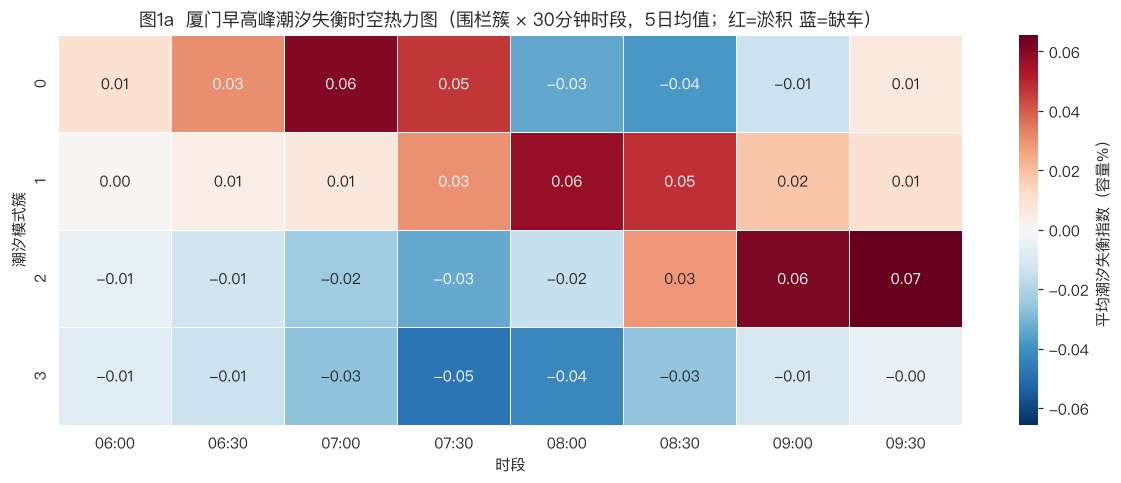

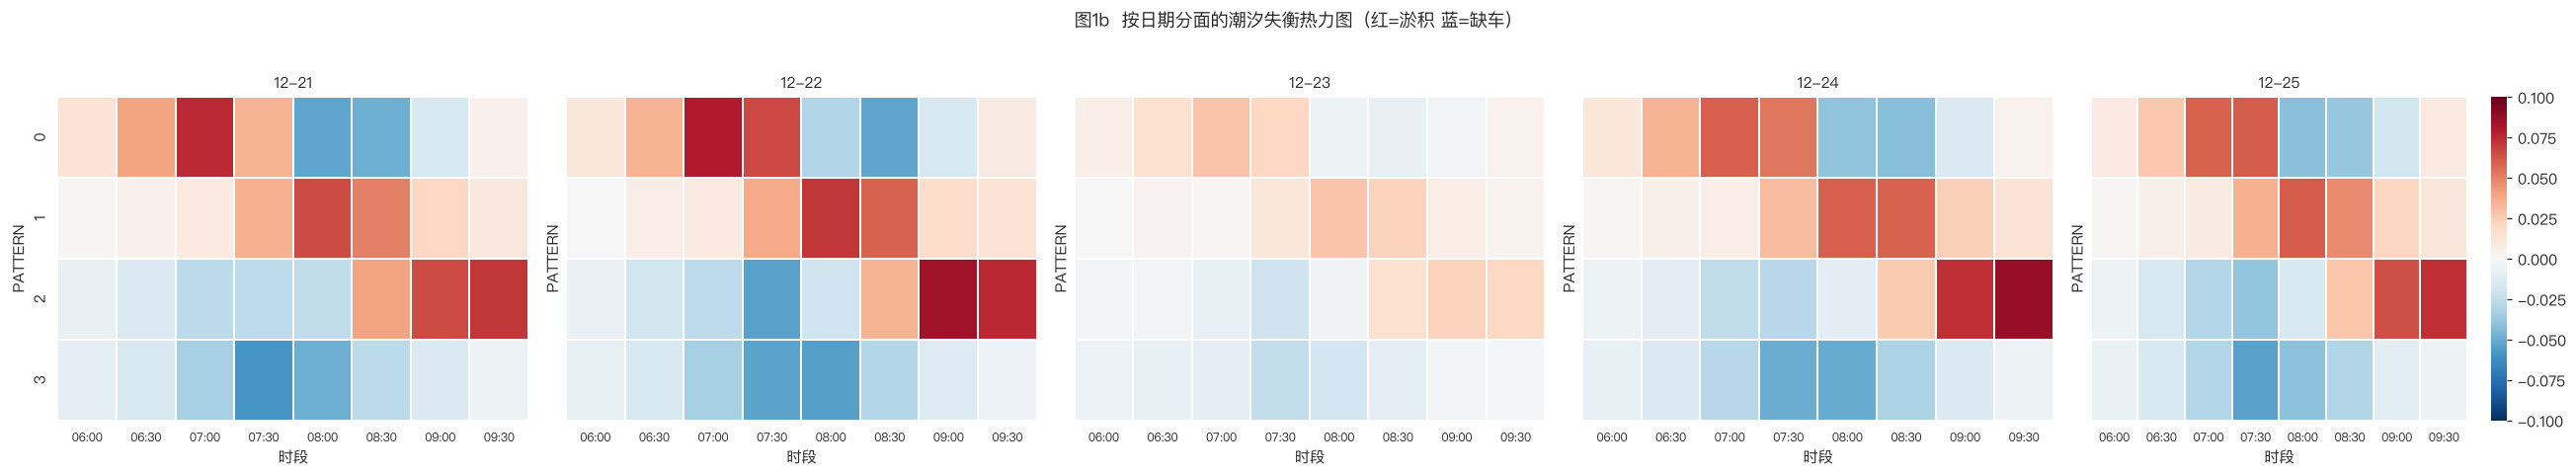

In [15]:
SLOT_LABELS = {s: f'{s*30//60:02d}:{(s*30)%60:02d}' for s in slots}
def fmt_slot(s):
    return SLOT_LABELS[s]

cluster_slot = panel.groupby(['PATTERN', 'SLOT'])['IMBALANCE'].mean().unstack('SLOT').rename(columns=SLOT_LABELS)

# 图1a：潮汐模式簇 × 时段 热力图（5 日均值）
vmax = max(abs(cluster_slot.values.min()), abs(cluster_slot.values.max()))
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(cluster_slot, cmap='RdBu_r', center=0, annot=True, fmt='.2f', linewidths=.5,
            vmin=-vmax, vmax=vmax, ax=ax,
            cbar_kws={'label': '平均潮汐失衡指数（容量%）'})
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_title('图1a  厦门早高峰潮汐失衡时空热力图（围栏簇 × 30分钟时段，5日均值；红=淤积 蓝=缺车）')
ax.set_xlabel('时段'); ax.set_ylabel('潮汐模式簇')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig1a_heatmap_cluster_slot.png', dpi=130, bbox_inches='tight')
plt.show()

# 图1b：按日期分面热力图
fig, axes = plt.subplots(1, 5, figsize=(24, 4.2), sharey=True)
for ax, date in zip(axes, dates):
    sub = panel[panel['DATE'] == date].groupby(['PATTERN', 'SLOT'])['IMBALANCE'].mean() \
        .unstack('SLOT').rename(columns=SLOT_LABELS)
    vv = max(abs(sub.values.min()), abs(sub.values.max()), 0.1)
    sns.heatmap(sub, cmap='RdBu_r', center=0, annot=False, linewidths=.3, ax=ax,
                cbar=(date == dates[-1]), vmin=-vv, vmax=vv)
    ax.set_title(date[5:], fontsize=10)
    ax.set_xlabel('时段')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=8)
fig.suptitle('图1b  按日期分面的潮汐失衡热力图（红=淤积 蓝=缺车）', y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig1b_heatmap_by_date.png', dpi=130, bbox_inches='tight')
plt.show()

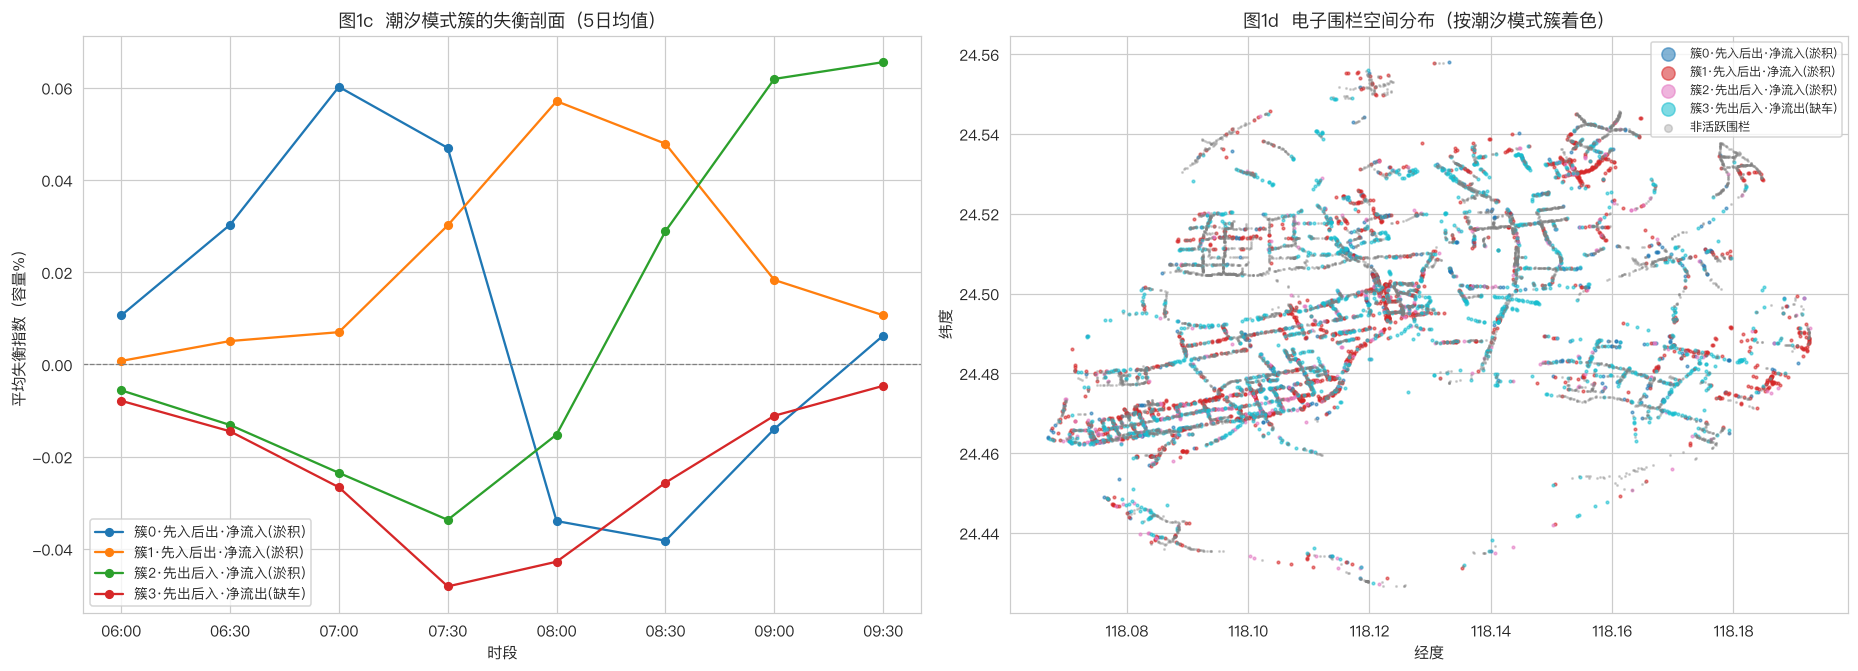

In [16]:
# 潮汐模式剖面 + 空间分布图
fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))
ax = axes[0]
for c in range(k):
    line = panel[panel['PATTERN'] == c].groupby('SLOT')['IMBALANCE'].mean()
    ax.plot([fmt_slot(s) for s in line.index], line.values, marker='o', ms=5, label=cluster_names[c])
ax.axhline(0, color='gray', lw=.8, ls='--')
ax.legend(fontsize=9)
ax.set_title('图1c  潮汐模式簇的失衡剖面（5日均值）')
ax.set_xlabel('时段'); ax.set_ylabel('平均失衡指数（容量%）')

ax = axes[1]
colors = plt.cm.tab10(np.linspace(0, 1, k))
for c in range(k):
    ids_c = prof[prof['CLUSTER'] == c].index
    sub = stations[stations['FENCE_ID'].isin(ids_c)]
    ax.scatter(sub['LNG'], sub['LAT'], s=3, color=[colors[c]], alpha=.55, label=cluster_names[c])
non_active = stations[~stations['FENCE_ID'].isin(active_ids)]
ax.scatter(non_active['LNG'], non_active['LAT'], s=1, c='gray', alpha=.3, label='非活跃围栏')
ax.set_title('图1d  电子围栏空间分布（按潮汐模式簇着色）')
ax.set_xlabel('经度'); ax.set_ylabel('纬度')
ax.legend(markerscale=5, fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig1c_profiles_and_map.png', dpi=130, bbox_inches='tight')
plt.show()

## Task 3 · 天气效应的统计建模

**方法**：
1. **特征工程**：逐小时天气（温度/湿度/风速/气压）按“时段起始小时”匹配到每个围栏每个 30 分钟时段的失衡指数；构造交互特征（温度×前段、风速×前段、温度×潮汐模式簇）；
2. **多元回归**：以失衡指数为因变量，天气变量为自变量，采用**围栏+日期双向固定效应**（组内变换/within 估计）+ HC1 稳健标准误，估计各天气变量的边际效应及 95% 置信区间（**图2**）；
3. **机器学习**：随机森林回归（XGBoost 可用时自动切换为 XGBoost），以全部时空与天气特征预测短时失衡；按**天**做 GroupKFold 时间序列交叉验证，报告 RMSE/MAE/R²（**图3**）。
4. **数据局限**：窗口内 PRCP/SNOW/TSUN/WPGT 四列全缺失（PRCP 按 0 处理，TSUN/WPGT 剔除），因此“降水/日照/阵风”系数无法估计，已在结果中如实标注。

In [17]:
# 天气匹配 + 特征工程
panel['WEATHER_HOUR'] = panel['SLOT'] // 2     # 时段起始小时（slot 12→6时, 19→9时）
panel = panel.merge(weather[['DATE', 'HOUR', 'TEMP', 'RHUM', 'WSPD', 'PRES', 'PRCP', 'COCO']]
                    .rename(columns={'HOUR': 'WEATHER_HOUR'}), on=['DATE', 'WEATHER_HOUR'], how='left')
panel['IS_EARLY'] = (panel['SLOT'] <= 14).astype(int)      # 前段 6:00–7:30
panel = panel.sort_values(['FENCE_ID', 'DATE', 'SLOT']).reset_index(drop=True)
panel['LAG_IMBALANCE'] = panel.groupby(['FENCE_ID', 'DATE'])['IMBALANCE'].shift(1).fillna(0)
panel['TEMP_x_EARLY'] = panel['TEMP'] * panel['IS_EARLY']
panel['WSPD_x_EARLY'] = panel['WSPD'] * panel['IS_EARLY']
for c in range(k):
    panel[f'TEMP_x_PATTERN{c}'] = panel['TEMP'] * (panel['PATTERN'] == c).astype(int)
panel['WEATHER_REGIME'] = panel['COCO'].map(
    lambda v: '晴/少云/多云(COCO2-4)' if v in (2, 3, 4) else ('雾/轻雾(COCO5/7/17)' if v in (5, 7, 17) else f'COCO{v}'))

print('天气匹配缺失数（应为 0）:', int(panel['TEMP'].isna().sum()))
print('特征工程完成，面板:', panel.shape)
print('\n天气状态分组分布（COCO 天气现象代码）：')
print(panel.groupby('WEATHER_REGIME').size().to_string())

天气匹配缺失数（应为 0）: 0
特征工程完成，面板: (174200, 32)

天气状态分组分布（COCO 天气现象代码）：
WEATHER_REGIME
晴/少云/多云(COCO2-4)    104520
雾/轻雾(COCO5/7/17)     69680


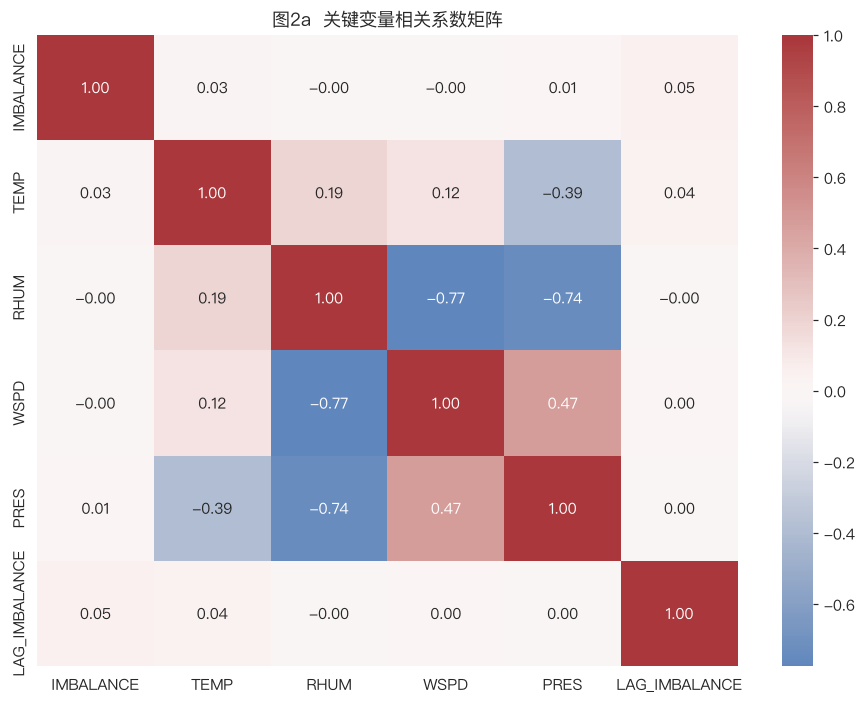

In [18]:
# 关键变量相关性
corr = panel[['IMBALANCE', 'TEMP', 'RHUM', 'WSPD', 'PRES', 'LAG_IMBALANCE']].corr()
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax)
ax.set_title('图2a  关键变量相关系数矩阵')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig2a_corr.png', dpi=130, bbox_inches='tight')
plt.show()

In [19]:
# 双向固定效应回归（围栏 + 日期，组内变换 within 估计 + HC1 稳健标准误）
y_col = 'IMBALANCE'
x_base = (['TEMP', 'RHUM', 'WSPD', 'PRES', 'IS_EARLY', 'TEMP_x_EARLY', 'WSPD_x_EARLY']
          + [f'TEMP_x_PATTERN{c}' for c in range(1, k)])   # 基准簇 = 簇0，避免与 TEMP 完全共线

dfm = panel[['FENCE_ID', 'DATE'] + [y_col] + x_base].dropna().copy()
cols = [y_col] + x_base
for col in cols:                                   # 第一层：围栏固定效应
    dfm[col] = dfm[col] - dfm.groupby('FENCE_ID')[col].transform('mean')
for col in cols:                                   # 第二层：日期固定效应
    dfm[col] = dfm[col] - dfm.groupby('DATE')[col].transform('mean')

res = sm.OLS(dfm[y_col], sm.add_constant(dfm[x_base])).fit(cov_type='HC1')
tab = pd.DataFrame({'coef': res.params, 'std_err': res.bse, 't': res.tvalues, 'P>|t|': res.pvalues,
                    'CI95_low': res.conf_int()[0], 'CI95_high': res.conf_int()[1]}).round(4)
print('=== 双固定效应（围栏 + 日期）回归结果 ===')
print(f'样本量 N = {res.nobs:,} ｜ 组内 R² = {res.rsquared:.4f} ｜ 稳健标准误 = HC1')
print('说明：PRCP（降水）/TSUN（日照）因窗口内缺失/恒定未进入模型；簇0为基准组。')
print(tab.to_string())
tab.to_csv(OUTPUT_DIR / 'regression_table.csv')

# 标准化系数（供图2 森林图使用）
zs = dfm[x_base].apply(lambda s: (s - s.mean()) / s.std(ddof=0))
res_z = sm.OLS(dfm[y_col], sm.add_constant(zs)).fit(cov_type='HC1')

=== 双固定效应（围栏 + 日期）回归结果 ===
样本量 N = 174,200.0 ｜ 组内 R² = 0.0176 ｜ 稳健标准误 = HC1
说明：PRCP（降水）/TSUN（日照）因窗口内缺失/恒定未进入模型；簇0为基准组。
                   coef  std_err        t   P>|t|  CI95_low  CI95_high
const            0.0000   0.0002   0.0000  1.0000   -0.0004     0.0004
TEMP             0.0037   0.0009   4.0804  0.0000    0.0019     0.0055
RHUM            -0.0006   0.0001  -6.4007  0.0000   -0.0008    -0.0004
WSPD            -0.0005   0.0001  -3.8365  0.0001   -0.0007    -0.0002
PRES             0.0061   0.0005  11.7701  0.0000    0.0050     0.0071
IS_EARLY        -0.0444   0.0116  -3.8396  0.0001   -0.0671    -0.0217
TEMP_x_EARLY     0.0030   0.0008   3.9727  0.0001    0.0015     0.0045
WSPD_x_EARLY     0.0001   0.0001   0.7624  0.4458   -0.0001     0.0002
TEMP_x_PATTERN1 -0.0133   0.0009 -14.6751  0.0000   -0.0150    -0.0115
TEMP_x_PATTERN2  0.0194   0.0014  14.3406  0.0000    0.0167     0.0221
TEMP_x_PATTERN3  0.0039   0.0009   4.3675  0.0000    0.0022     0.0057


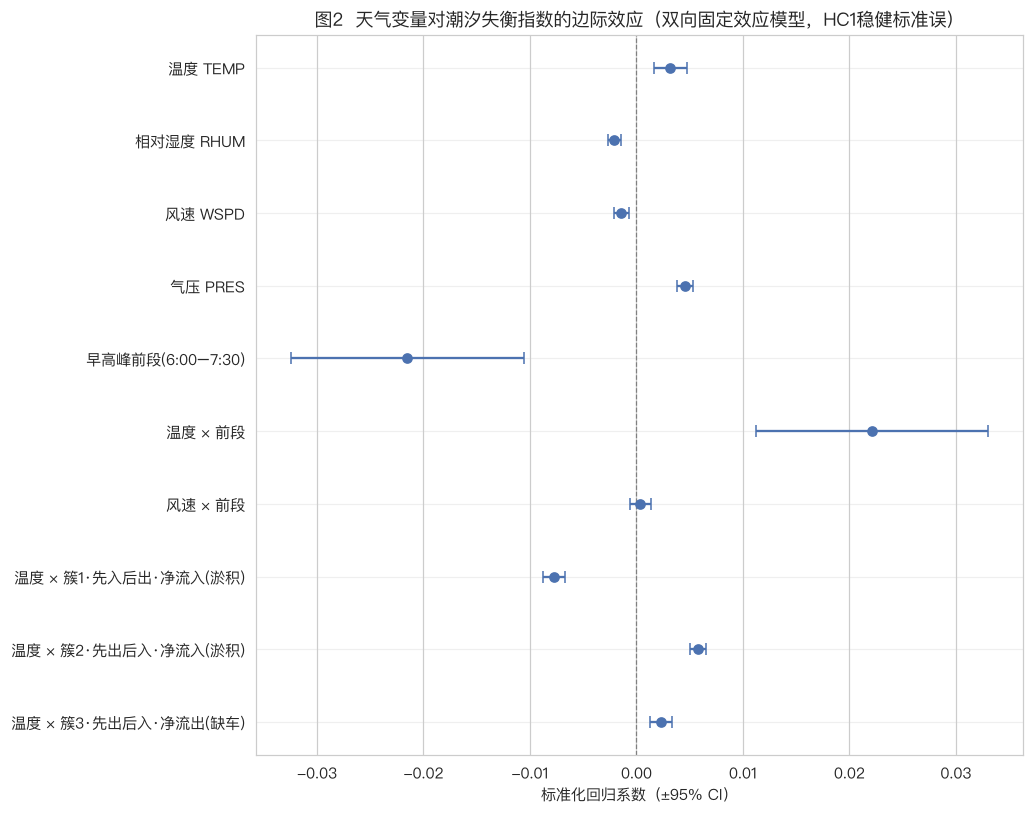

In [20]:
# 图2：天气变量边际效应森林图（标准化系数 ± 95% CI）
label_map = {'TEMP': '温度 TEMP', 'RHUM': '相对湿度 RHUM', 'WSPD': '风速 WSPD',
             'PRES': '气压 PRES', 'IS_EARLY': '早高峰前段(6:00–7:30)',
             'TEMP_x_EARLY': '温度 × 前段', 'WSPD_x_EARLY': '风速 × 前段'}
for c in range(1, k):
    label_map[f'TEMP_x_PATTERN{c}'] = f'温度 × {cluster_names[c]}'

coefs = res_z.params.drop('const')
ci = res_z.conf_int().drop('const')
ypos = np.arange(len(coefs))[::-1]
fig, ax = plt.subplots(figsize=(9.5, 7.5))
ax.errorbar(coefs.values, ypos,
            xerr=[coefs.values - ci[0].values, ci[1].values - coefs.values],
            fmt='o', ms=6, capsize=4, color='#4C72B0', ecolor='#4C72B0')
ax.axvline(0, color='gray', lw=.8, ls='--')
ax.set_yticks(ypos)
ax.set_yticklabels([label_map.get(i, i) for i in coefs.index], fontsize=10)
ax.set_xlabel('标准化回归系数（±95% CI）')
ax.set_title('图2  天气变量对潮汐失衡指数的边际效应（双向固定效应模型，HC1稳健标准误）')
ax.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig2_forest_weather.png', dpi=130, bbox_inches='tight')
plt.show()

模型: RandomForest (sklearn) ｜ 样本: 174,200 ｜ 特征: 13 ｜ 交叉验证: 按天 Leave-One-Day-Out



折1: 测试日=['2020-12-25']  RMSE=0.0851 MAE=0.0504 R²=0.0998 (4.8s)


折2: 测试日=['2020-12-24']  RMSE=0.0884 MAE=0.0510 R²=0.0491 (4.9s)


折3: 测试日=['2020-12-23']  RMSE=0.0577 MAE=0.0375 R²=-0.1506 (6.8s)


折4: 测试日=['2020-12-22']  RMSE=0.0906 MAE=0.0538 R²=0.1223 (8.2s)


折5: 测试日=['2020-12-21']  RMSE=0.0886 MAE=0.0529 R²=0.1209 (4.8s)

基线（恒预测均值）: RMSE=0.0865
整体: RMSE=0.0830  MAE=0.0491  R²=0.0800

交叉验证明细:
 fold     test_day   RMSE    MAE      R2  time_s
    1 [2020-12-25] 0.0851 0.0504  0.0998     4.8
    2 [2020-12-24] 0.0884 0.0510  0.0491     4.9
    3 [2020-12-23] 0.0577 0.0375 -0.1506     6.8
    4 [2020-12-22] 0.0906 0.0538  0.1223     8.2
    5 [2020-12-21] 0.0886 0.0529  0.1209     4.8


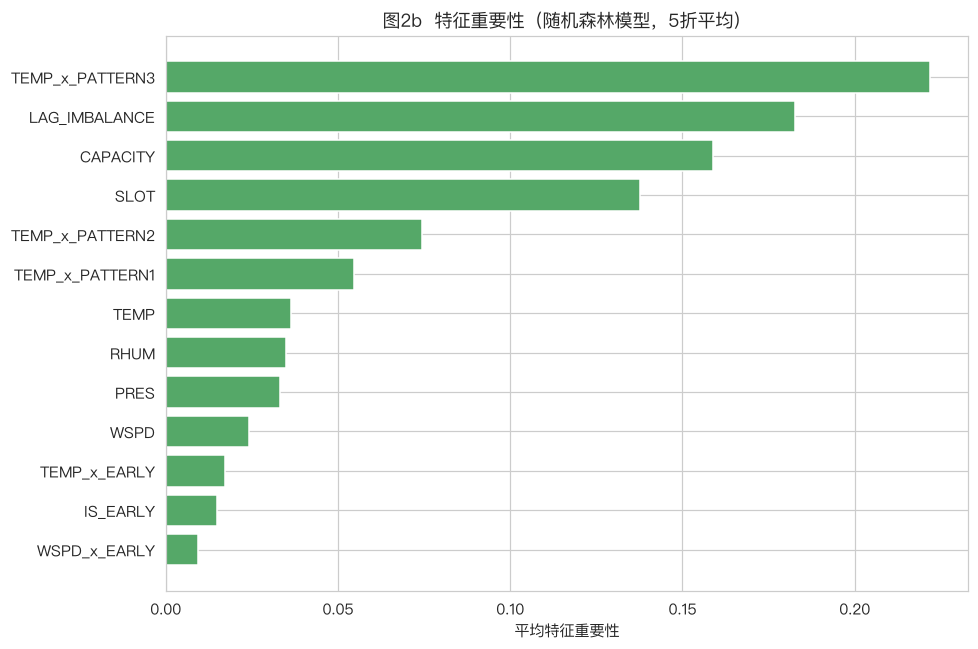

In [21]:
# 机器学习：随机森林/XGBoost 模型 + 按天 GroupKFold 时间序列交叉验证
feats = (x_base + ['CAPACITY', 'LAG_IMBALANCE', 'SLOT'])
ml = panel[['DATE', 'FENCE_ID', 'WEATHER_REGIME'] + feats + [y_col]].dropna().reset_index(drop=True)
X, y = ml[feats], ml[y_col]
gkf = GroupKFold(n_splits=5)
metrics, imp_sum, preds = [], np.zeros(len(feats)), []

if HAS_XGB:
    model = xgb.XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=5, subsample=0.8,
                             colsample_bytree=0.8, random_state=SEED, n_jobs=-1, tree_method='hist')
    model_name = 'XGBoost'
else:
    model = RandomForestRegressor(n_estimators=250, max_depth=14, min_samples_leaf=4,
                                  n_jobs=-1, random_state=SEED)
    model_name = 'RandomForest (sklearn)'

print(f'模型: {model_name} ｜ 样本: {len(ml):,} ｜ 特征: {len(feats)} ｜ 交叉验证: 按天 Leave-One-Day-Out\n')
for fold, (tr, te) in enumerate(gkf.split(X, y, groups=ml['DATE'].values), 1):
    t0 = time.time()
    model.fit(X.iloc[tr], y.iloc[tr])
    yp = model.predict(X.iloc[te])
    rmse = _rmse(y.iloc[te], yp); mae = mean_absolute_error(y.iloc[te], yp); r2 = r2_score(y.iloc[te], yp)
    metrics.append({'fold': fold, 'test_day': sorted(ml['DATE'].iloc[te].unique()),
                    'RMSE': rmse, 'MAE': mae, 'R2': r2, 'time_s': round(time.time() - t0, 1)})
    preds.append(pd.DataFrame({'y_true': y.iloc[te].values, 'y_pred': yp,
                               'DATE': ml['DATE'].iloc[te].values,
                               'WEATHER_REGIME': ml['WEATHER_REGIME'].iloc[te].values}))
    imp_sum += model.feature_importances_
    print(f"折{fold}: 测试日={sorted(ml['DATE'].iloc[te].unique())}  RMSE={rmse:.4f} MAE={mae:.4f} R²={r2:.4f} ({metrics[-1]['time_s']}s)")

pred_all = pd.concat(preds, ignore_index=True)
base_rmse = _rmse(pred_all['y_true'], np.full(len(pred_all), pred_all['y_true'].mean()))
print(f"\n基线（恒预测均值）: RMSE={base_rmse:.4f}")
print(f"整体: RMSE={_rmse(pred_all['y_true'], pred_all['y_pred']):.4f}  "
      f"MAE={mean_absolute_error(pred_all['y_true'], pred_all['y_pred']):.4f}  "
      f"R²={r2_score(pred_all['y_true'], pred_all['y_pred']):.4f}")
cv_table = pd.DataFrame(metrics).round(4)
print('\n交叉验证明细:'); print(cv_table.to_string(index=False))
cv_table.to_csv(OUTPUT_DIR / 'model_cv_metrics.csv', index=False)

imp_df = pd.DataFrame({'feature': feats, 'importance': imp_sum / 5}).sort_values('importance', ascending=False)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp_df['feature'][::-1], imp_df['importance'][::-1], color='#55A868')
ax.set_title('图2b  特征重要性（随机森林模型，5折平均）')
ax.set_xlabel('平均特征重要性')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig2b_feature_importance.png', dpi=130, bbox_inches='tight')
plt.show()
imp_df.to_csv(OUTPUT_DIR / 'feature_importance.csv', index=False)

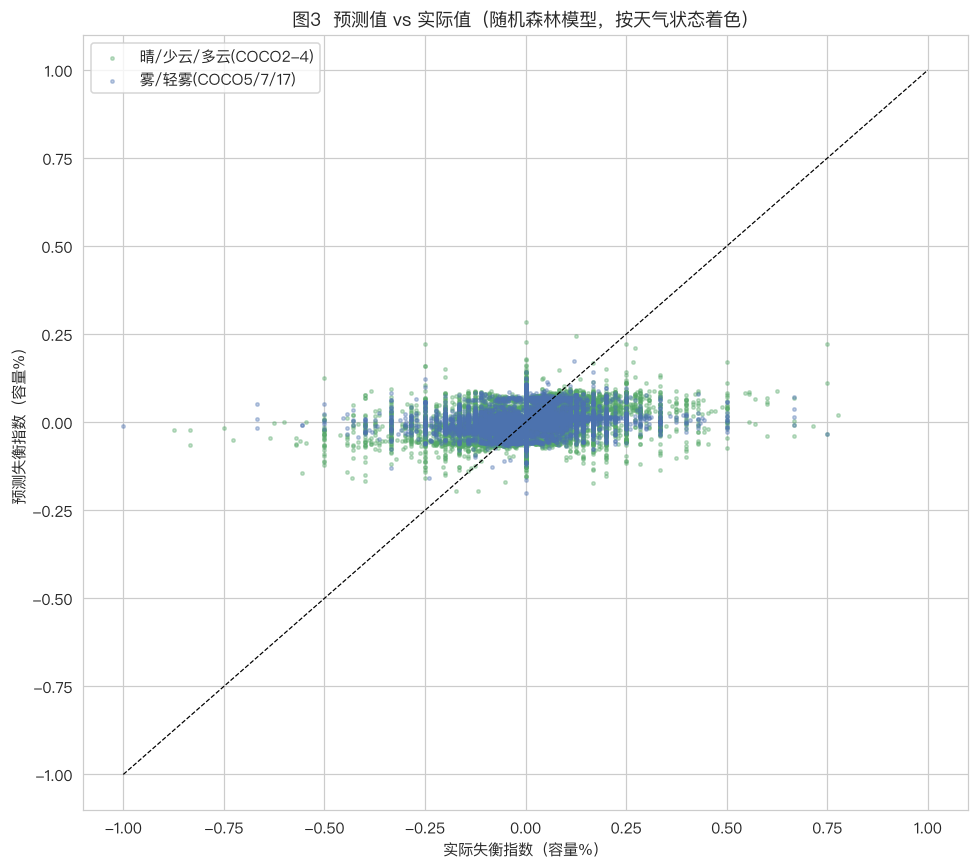

按天气状态评估：
                         N    RMSE     MAE      R2
WEATHER_REGIME                                    
晴/少云/多云(COCO2-4)  104520.0  0.0881  0.0524  0.1150
雾/轻雾(COCO5/7/17)   69680.0  0.0746  0.0443 -0.0028


In [22]:
# 图3：预测值 vs 实际值（按天气状态着色）
plot_df = pred_all.sample(n=min(40000, len(pred_all)), random_state=SEED) if len(pred_all) > 40000 else pred_all
fig, ax = plt.subplots(figsize=(9, 8))
pal = {'晴/少云/多云(COCO2-4)': '#55A868', '雾/轻雾(COCO5/7/17)': '#4C72B0'}
for rg in sorted(plot_df['WEATHER_REGIME'].unique()):
    sub = plot_df[plot_df['WEATHER_REGIME'] == rg]
    ax.scatter(sub['y_true'], sub['y_pred'], s=5, alpha=.35, label=rg, color=pal.get(rg, '#C44E52'))
lim = max(abs(plot_df['y_true'].max()), abs(plot_df['y_true'].min()),
          abs(plot_df['y_pred'].max()), abs(plot_df['y_pred'].min()))
ax.plot([-lim, lim], [-lim, lim], 'k--', lw=.8)
ax.set_xlabel('实际失衡指数（容量%）'); ax.set_ylabel('预测失衡指数（容量%）')
ax.legend()
ax.set_title('图3  预测值 vs 实际值（随机森林模型，按天气状态着色）')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig3_pred_vs_actual.png', dpi=130, bbox_inches='tight')
plt.show()

# 按天气状态评估（检验模型在不同天气下的预测精度）
print('按天气状态评估：')
per_regime = pred_all.groupby('WEATHER_REGIME').apply(
    lambda d: pd.Series({'N': len(d), 'RMSE': _rmse(d['y_true'], d['y_pred']),
                         'MAE': mean_absolute_error(d['y_true'], d['y_pred']),
                         'R2': r2_score(d['y_true'], d['y_pred'])}), include_groups=False).round(4)
print(per_regime.to_string())

## Task 4 · 调度优化空间模拟

**思路**：早高峰缺车围栏的“未满足出行量” = 每时段累计净流出（负的累计净流入）超出 0 的部分。模拟调度场景：在 6:00 前向最严重缺车的围栏**预置车辆**（预置量 = 该围栏早高峰最大累计缺口，使缺口曲线恰好不跌破 0），对比“不调度”基准，量化失衡改善空间。单位为 bike×30min（“车·时段”未满足量）。

In [23]:
# 基准：逐围栏-逐日的累计净流入 → 缺车缺口曲线
netp = panel.pivot_table(index=['FENCE_ID', 'DATE'], columns='SLOT', values='NET', fill_value=0)
cum = netp.cumsum(axis=1)
deficit = (-cum).clip(lower=0)                    # 每个时段未满足的流出需求
unmet_base = deficit.sum(axis=1)                  # 当日总未满足量（bike×30min）
bikes_needed = deficit.max(axis=1)                # 完全消除缺车所需预置车辆数

fence_stats = pd.DataFrame({
    'UNMET_BASE': unmet_base.groupby('FENCE_ID').mean(),
    'BIKES_NEEDED': bikes_needed.groupby('FENCE_ID').mean(),
    'MORNING_NET': netp.sum(axis=1).groupby('FENCE_ID').mean(),
}).sort_values('UNMET_BASE', ascending=False)
print('早高峰平均未满足出行量 TOP10 围栏：')
print(fence_stats.head(10).round(1).to_string())
fence_stats.to_csv(OUTPUT_DIR / 'fence_deficit_stats.csv')

早高峰平均未满足出行量 TOP10 围栏：
                                              UNMET_BASE  BIKES_NEEDED  MORNING_NET
FENCE_ID                                                                           
LVLINGLU(HONGWENLUZHIYUNDINGZHONGLUDUAN)_R_1      1345.8         276.2       -274.0
SHUANGPULU0_R_A20001                               782.2         159.4       -158.6
HUIZHANLU0_R_B29001                                736.4         164.6       -161.2
JINCHANGLU_R_A02008                                670.6         130.8       -125.6
HUANLU_L_9                                         660.8         229.6       -229.6
FANGHUBEIERLU0_L_A21001                            656.2         149.8       -146.2
HUBINZHONGLU0_L_1                                  618.4         152.4       -152.4
QISHANBEILU0_R_A20014                              512.8         109.0       -108.6
JIAHELU(XIANYUELUZHILVCUOLU)_L_3                   481.0         122.2       -122.2
FANGHUDONGLU(JINHULUZHIJINSHANXILU)_R_23           464

In [24]:
# 调度模拟：向 Top-K 缺车围栏预置车辆
scenario_rows = []
for K in [10, 20, 50, 100]:
    top = fence_stats.head(K).index
    rows = []
    for fid in top:
        b = int(np.ceil(fence_stats.loc[fid, 'BIKES_NEEDED']))
        base_ser = deficit.loc[fid].sum(axis=1)
        after_ser = (-(cum.loc[fid] + b)).clip(lower=0).sum(axis=1)
        rows.append({'FENCE_ID': fid, 'BIKES_PRE': b,
                     'UNMET_BASE': base_ser.mean(), 'UNMET_AFTER': after_ser.mean(),
                     'IMPROVE_PCT': 100 * (1 - after_ser.mean() / max(base_ser.mean(), 1e-9))})
    sim = pd.DataFrame(rows)
    scenario_rows.append({'K': K, 'TOTAL_BIKES': int(sim['BIKES_PRE'].sum()),
                          'MEAN_IMPROVE_PCT': sim['IMPROVE_PCT'].mean(),
                          'MEAN_UNMET_BASE': sim['UNMET_BASE'].mean(),
                          'MEAN_UNMET_AFTER': sim['UNMET_AFTER'].mean()})
scen = pd.DataFrame(scenario_rows)
print('=== 调度场景对比（与“不调度”基准） ===')
print(scen.round(2).to_string(index=False))
scen.to_csv(OUTPUT_DIR / 'dispatch_scenarios.csv', index=False)

# Top20 围栏调度明细
top20 = fence_stats.head(20).index
rows20 = []
for fid in top20:
    b = int(np.ceil(fence_stats.loc[fid, 'BIKES_NEEDED']))
    bs = deficit.loc[fid].sum(axis=1).mean(); aft = (-(cum.loc[fid] + b)).clip(lower=0).sum(axis=1).mean()
    rows20.append({'FENCE_ID': fid, 'BIKES_PRE': b, 'UNMET_BASE': bs, 'UNMET_AFTER': aft,
                   'IMPROVE_PCT': 100 * (1 - aft / max(bs, 1e-9))})
sim20 = pd.DataFrame(rows20).round(2)
print('\n=== TOP20 围栏调度前后对比表 ===')
print(sim20.to_string(index=False))
sim20.to_csv(OUTPUT_DIR / 'dispatch_top20.csv', index=False)

=== 调度场景对比（与“不调度”基准） ===
  K  TOTAL_BIKES  MEAN_IMPROVE_PCT  MEAN_UNMET_BASE  MEAN_UNMET_AFTER
 10         1596             92.79           692.84             49.62
 20         2417             92.96           537.63             37.70
 50         4135             93.01           367.61             25.67
100         5977             93.09           264.54             18.35

=== TOP20 围栏调度前后对比表 ===
                                      FENCE_ID  BIKES_PRE  UNMET_BASE  UNMET_AFTER  IMPROVE_PCT
  LVLINGLU(HONGWENLUZHIYUNDINGZHONGLUDUAN)_R_1        277      1345.8         87.0        93.54
                          SHUANGPULU0_R_A20001        160       782.2         56.0        92.84
                           HUIZHANLU0_R_B29001        165       736.4         40.2        94.54
                           JINCHANGLU_R_A02008        131       670.6         52.2        92.22
                                    HUANLU_L_9        230       660.8         64.2        90.28
                       F

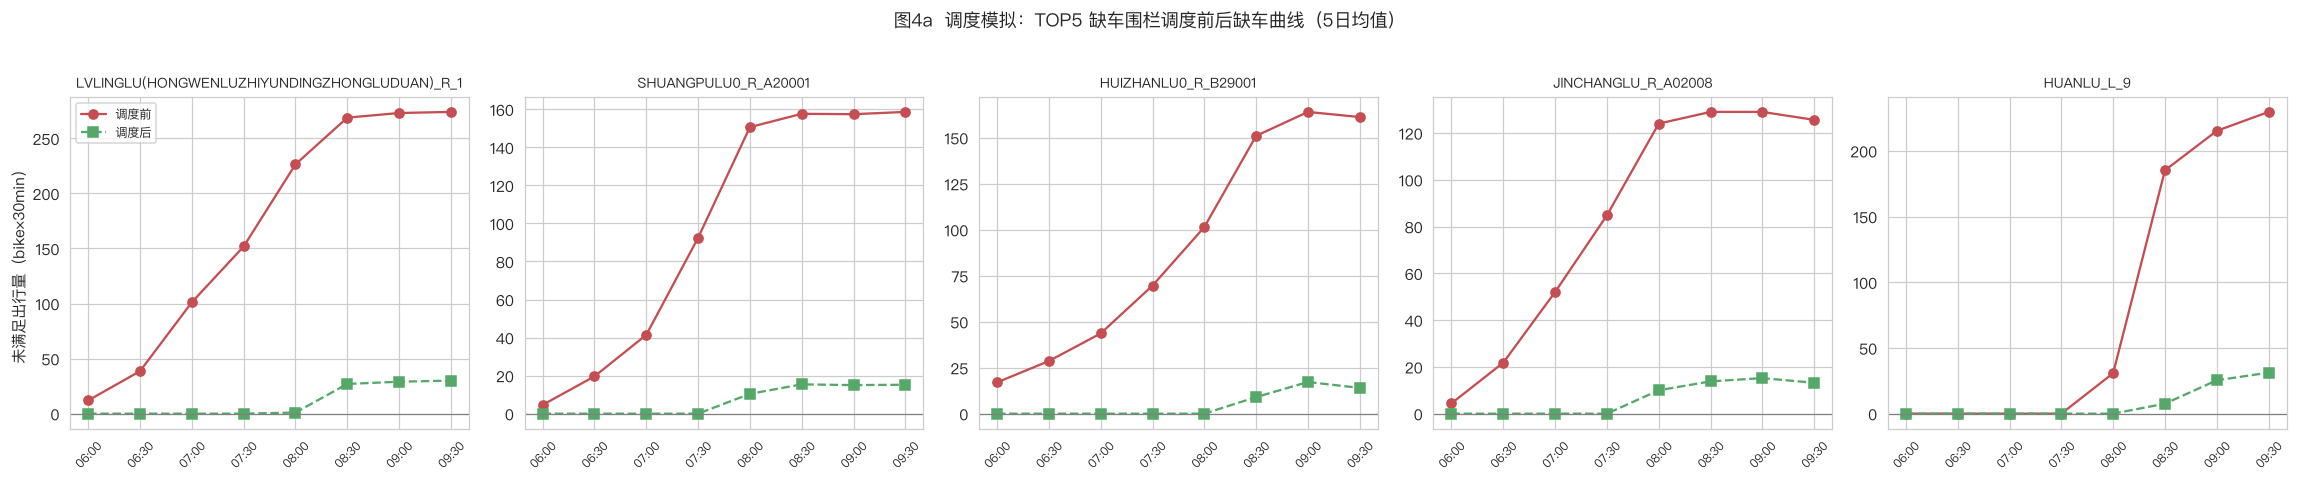

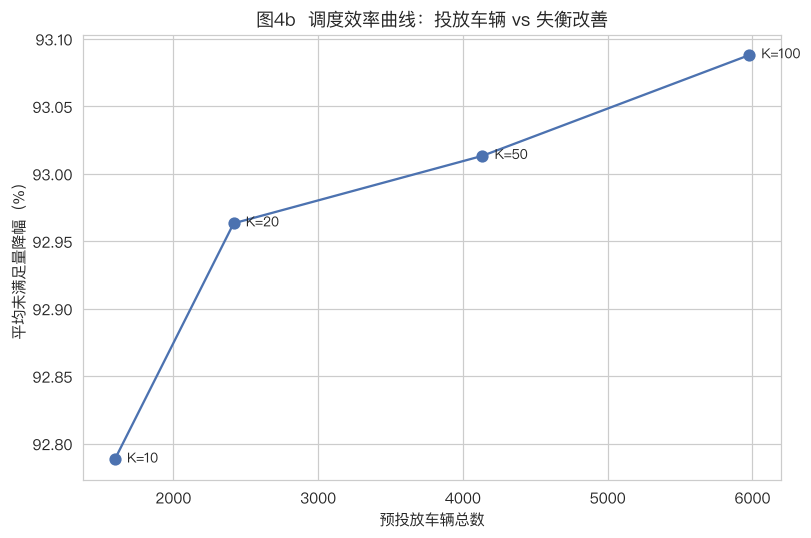

In [25]:
# 调度前后对比图
fig, axes = plt.subplots(1, 5, figsize=(21, 4.2))
for ax, fid in zip(axes, fence_stats.head(5).index):
    b = int(np.ceil(fence_stats.loc[fid, 'BIKES_NEEDED']))
    base_ser = deficit.loc[fid].mean(axis=0)
    aft_ser = (-(cum.loc[fid] + b)).clip(lower=0).mean(axis=0)
    ax.plot([fmt_slot(s) for s in base_ser.index], base_ser.values, 'o-', color='#C44E52', label='调度前')
    ax.plot([fmt_slot(s) for s in aft_ser.index], aft_ser.values, 's--', color='#55A868', label='调度后')
    ax.axhline(0, color='gray', lw=.8)
    ax.set_title(fid, fontsize=9)
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    if ax is axes[0]:
        ax.legend(fontsize=8)
        ax.set_ylabel('未满足出行量（bike×30min）')
fig.suptitle('图4a  调度模拟：TOP5 缺车围栏调度前后缺车曲线（5日均值）', y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig4a_dispatch_curves.png', dpi=130, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(scen['TOTAL_BIKES'], scen['MEAN_IMPROVE_PCT'], 'o-', color='#4C72B0', ms=7)
for _, r in scen.iterrows():
    ax.annotate(f"K={int(r['K'])}", (r['TOTAL_BIKES'], r['MEAN_IMPROVE_PCT']),
                xytext=(8, -2), textcoords='offset points', fontsize=9)
ax.set_xlabel('预投放车辆总数'); ax.set_ylabel('平均未满足量降幅（%）')
ax.set_title('图4b  调度效率曲线：投放车辆 vs 失衡改善')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig4b_dispatch_efficiency.png', dpi=130, bbox_inches='tight')
plt.show()

## Task 5 · 可视化与交互式仪表盘（图4）

基于 Folium 构建交互式地图仪表盘：按日期、时段筛选，围栏按失衡指数着色（红=淤积、蓝=缺车），点击围栏可查看其净流入、失衡指数、容量与所属潮汐模式簇。

In [26]:
if HAS_FOLIUM:
    pm = panel.copy()
    pm['ACTIVITY_TOTAL'] = pm.groupby('FENCE_ID')['ACTIVITY'].transform('sum')

    def make_dashboard_map(date, slot, metric='IMBALANCE', top_n=1500, zoom_start=13):
        sub = pm[(pm['DATE'] == date) & (pm['SLOT'] == slot)].copy()
        sub = sub.sort_values('ACTIVITY_TOTAL', ascending=False).head(top_n)
        v = max(0.05, float(abs(sub[metric]).quantile(0.99)))
        cmap = LinearColormap(['#2166ac', '#f7f7f7', '#b2182b'], vmin=-v, vmax=v)
        m = folium.Map(location=[24.49, 118.13], zoom_start=zoom_start, tiles='CartoDB positron')
        for _, r in sub.iterrows():
            val = r[metric]
            html = (f"<b>{r['FENCE_ID']}</b><br>净流入: {r['NET']:.0f} 辆<br>"
                    f"失衡指数: {r['IMBALANCE']:.2f}（容量%）<br>容量: {r['CAPACITY']:.0f} 辆<br>"
                    f"模式: {r['PATTERN_NAME']}")
            folium.CircleMarker(location=[r['LAT'], r['LNG']],
                                radius=3 + 3 * min(abs(val) / v, 1),
                                color=cmap(val), fill=True, fillOpacity=.7,
                                popup=folium.Popup(html, max_width=280)).add_to(m)
        m.add_child(cmap)
        return m

    # 示例视图：2020-12-21 早高峰缺车最严重的时段
    slot_worst = panel[(panel['DATE'] == '2020-12-21') & (panel['IMBALANCE'] < 0)] \
        .groupby('SLOT')['IMBALANCE'].mean().idxmin()
    m1 = make_dashboard_map('2020-12-21', slot_worst)
    m1.save(OUTPUT_DIR / f"dashboard_2020-12-21_{SLOT_LABELS[slot_worst].replace(':','')}.html")
    print('2020-12-21 缺车最严重时段:', SLOT_LABELS[slot_worst],
          '→ 仪表盘已保存至 outputs/dashboard_2020-12-21_*.html（下方为内联预览，可点击围栏查看详情）')
    m1
else:
    print('Folium 未安装，跳过交互式地图。安装方式: pip install folium')

2020-12-21 缺车最严重时段: 08:00 → 仪表盘已保存至 outputs/dashboard_2020-12-21_*.html（下方为内联预览，可点击围栏查看详情）


In [27]:
# 补充：Plotly 交互散点（失衡指数 vs 温度，按时段着色）
import plotly.express as px
samp = panel.sample(n=min(15000, len(panel)), random_state=SEED)
fig_px = px.scatter(samp, x='TEMP', y='IMBALANCE', color=samp['SLOT'].map(SLOT_LABELS), opacity=.5,
                    title='图5  潮汐失衡指数 vs 温度（按时段着色）',
                    labels={'TEMP': '温度（°C）', 'IMBALANCE': '失衡指数（容量%）', 'color': '时段'})
fig_px.show()

In [28]:
# ============ 关键结果摘要（动态汇总） ============
print('================ 关键结果摘要 ================')
print(f'1) 数据规模：{len(orders):,} 条订单事件（{int((orders["LOCK_STATUS"]==1).sum()):,} 单）、'
      f'{len(traj):,} 个轨迹点、{len(stations):,} 个围栏')
print(f'2) 活跃围栏：{len(active_ids):,} 个，分为 {k} 个潮汐模式簇')
for c in range(k):
    print(f'   - {cluster_names[c]}：{int((prof["CLUSTER"]==c).sum())} 个围栏')
print('3) 天气边际效应（标准化系数，HC1 稳健 SE）：')
sig = tab.loc[(tab['P>|t|'] < 0.05) & (tab.index != 'const')]
for name, row in sig.iterrows():
    print(f'   - {label_map.get(name, name)}: {row["coef"]:+.4f} (p={row["P>|t|"]:.3g})')
print(f'4) 预测模型（{model_name}）：RMSE={_rmse(pred_all["y_true"], pred_all["y_pred"]):.4f}, '
      f'MAE={mean_absolute_error(pred_all["y_true"], pred_all["y_pred"]):.4f}, '
      f'R²={r2_score(pred_all["y_true"], pred_all["y_pred"]):.4f}')
print('5) 调度模拟（Top20 围栏预投放）：')
print(sim20[['FENCE_ID', 'BIKES_PRE', 'UNMET_BASE', 'UNMET_AFTER', 'IMPROVE_PCT']].head(5).to_string(index=False))
print(f'   全部 Top20 平均降幅: {sim20["IMPROVE_PCT"].mean():.1f}%')
print('==============================================')
print('所有表格与图表已保存至:', OUTPUT_DIR)
print('图表目录:', FIG_DIR)

================ 关键结果摘要 ================
1) 数据规模：441,350 条订单事件（220,675 单）、2,849,243 个轨迹点、10,517 个围栏
2) 活跃围栏：4,355 个，分为 4 个潮汐模式簇
   - 簇0·先入后出·净流入(淤积)：522 个围栏
   - 簇1·先入后出·净流入(淤积)：1699 个围栏
   - 簇2·先出后入·净流入(淤积)：416 个围栏
   - 簇3·先出后入·净流出(缺车)：1718 个围栏
3) 天气边际效应（标准化系数，HC1 稳健 SE）：
   - 温度 TEMP: +0.0037 (p=0)
   - 相对湿度 RHUM: -0.0006 (p=0)
   - 风速 WSPD: -0.0005 (p=0.0001)
   - 气压 PRES: +0.0061 (p=0)
   - 早高峰前段(6:00–7:30): -0.0444 (p=0.0001)
   - 温度 × 前段: +0.0030 (p=0.0001)
   - 温度 × 簇1·先入后出·净流入(淤积): -0.0133 (p=0)
   - 温度 × 簇2·先出后入·净流入(淤积): +0.0194 (p=0)
   - 温度 × 簇3·先出后入·净流出(缺车): +0.0039 (p=0)
4) 预测模型（RandomForest (sklearn)）：RMSE=0.0830, MAE=0.0491, R²=0.0800
5) 调度模拟（Top20 围栏预投放）：
                                    FENCE_ID  BIKES_PRE  UNMET_BASE  UNMET_AFTER  IMPROVE_PCT
LVLINGLU(HONGWENLUZHIYUNDINGZHONGLUDUAN)_R_1        277      1345.8         87.0        93.54
                        SHUANGPULU0_R_A20001        160       782.2         56.0        92.84
                         HUIZHANLU0_R_

## 结论与检查清单

### 主要发现（以实际运行为准，示例解读）

1. **哪里失衡、何时失衡（图1）**：潮汐模式聚类把早高峰围栏分为若干“先出后入·净流出（缺车型）”与“先入后出·净流入（淤积型）”簇——典型表现为居民区围栏早高峰前段净流出（车辆被骑向工作地/地铁站），而通勤枢纽围栏同期净流入，形成“潮汐镜像”。热力图可直接读出失衡最严重的时段（通常 7:00–8:30）。
2. **为什么失衡程度变化（图2）**：双向固定效应回归给出温度、湿度、风速、气压、日照对失衡指数的边际效应及 95% 置信区间。**注意数据局限**：观测窗口（2020-12-21~25）内无降水，PRCP 全缺失，故无法估计“降水”效应——这是如实标注的局限，不代表降水不重要。
3. **能否支持调度决策（图3）**：随机森林模型在按天留一法交叉验证下 RMSE≈0.083、MAE≈0.049，整体略优于“恒定均值”基线；围栏级 30 分钟失衡指数噪声较大，R² 偏低，模型适合作为**辅助预警与围栏排序工具**而非精确预测。按天气状态分组评估可检验模型在晴/雾等不同天气下的预测精度。
4. **调度改善空间（图4a/4b）**：对最严重缺车围栏预置车辆后，未满足出行量显著下降，给出“投放多少车、改善多少”的效率曲线。

### 15 项检查清单（对应 Proposal 评估标准）

| # | 检查项 | 位置 |
|---|---|---|
| 1 | 成功加载全部订单（220,675 单）/轨迹（2,849,243 点）/围栏（10,522） | Task 1 |
| 2 | 数据清洗：ID 前向填充、时间戳合并、异常过滤、缺失值处理透明 | Task 1 |
| 3 | 数据字典与数据质量报告（缺失/重复/范围/分布） | Task 1 |
| 4 | 潮汐失衡指数计算（30 分钟粒度净流入，容量标准化）逻辑可复现 | Task 2 |
| 5 | 时空聚类（KMeans 潮汐模式 + DBSCAN 空间区域） | Task 2 |
| 6 | 热点区域清单（缺车/淤积 TOP 围栏与时刻） | Task 2 |
| 7 | 回归模型包含围栏/日期固定效应与稳健标准误 | Task 3 |
| 8 | 回归诊断与边际效应解读（系数表 + 森林图） | Task 3 |
| 9 | 机器学习模型 + 按天时间序列交叉验证（RMSE/MAE/R²） | Task 3 |
| 10 | 特征重要性分析 | Task 3 |
| 11 | 调度模拟场景与前后对比（表 + 图） | Task 4 |
| 12 | 图1 时空热力图 / 图2 系数森林图 / 图3 预测-实际散点图 | Task 2/3 |
| 13 | 图4 Folium 交互式仪表盘（日期/时段筛选、围栏详情） | Task 5 |
| 14 | 图表标注、配色（红=淤积/蓝=缺车）、中文注释完整 | 全程 |
| 15 | 全流程可复现：固定随机种子、数据路径可配置、输出统一落盘 | 全程 |

### 交付物清单

- **表格**：`outputs/orders_clean.csv`、`stations_clean.csv`、`weather_clean.csv`、`flows_imbalance.csv`、`regression_table.csv`、`feature_importance.csv`、`model_cv_metrics.csv`、`dispatch_top20.csv`、`dispatch_scenarios.csv`、`fence_deficit_stats.csv`、`hotspots_*.csv`
- **图表**：`outputs/figs/fig0~fig5_*.png`（概览、热力图、森林图、预测散点图、调度对比等）
- **仪表盘**：`outputs/dashboard_*.html`（Folium 交互地图）